# Two-Stage Retrobiosynthesis Showcase: Bond-Level Enzymatic Reverse Peeling & Fungal-Iterative to Bacterial-Modular Assembly-Line Conversion

This notebook contains two figure types for each target:
1. **Bond-Specific Enzymatic Reverse-Peeling Reaction Scheme:**
   - **Blue Bond Highlight (`O—C(=O)` / `C—N` / `O—C1'`):** Intermolecular bond cleaved by reverse acyltransferase (`LovD`, `Rule 11`), glycosyltransferase (`DesVII`, `Rule 13`), or NRPS condensation (`TmcA/RapP`, `Rule 20/24`), with a curved branch arrow pointing to the **detached monomer** (`2-methylbutanoic acid`, `glycine`, `6-deoxysugar`).
   - **Orange Bond Highlight (`C—C` / `C—O`):** Intramolecular ring bond(s) broken by reverse carbocyclization / retro-$[4+2]$ Diels-Alder (`SpnF / LovB`, `Rule 0`), cyclic ether unzipping (`MonBI / Lsd19`, `Rule 19/32`), Baeyer-Villiger lactone excision (`MtmOIV`, `Rule 5`), Dieckmann tetramate opening (`TmcA`, `Rule 22`), spirotetronate retro-DA (`AbyU`, `Rule 17`), or P450 epoxide/C–H deoxygenation (`AbyE / EryF`, `Rule 3/4`).
2. **Module-by-Module Catalytic Domain-Bubble & Growing Acyl-S-ACP Assembly-Line Diagram:**
   - Contrasts the **Native Fungal Iterative hrPKS (`LovB + trans-ER LovC`)** looping 8× over a single active site against **Our Model's Proposed Bacterial Modular Type I PKS (`M0–M8`)** with green-highlighted $\alpha,\beta$ extension units, circular `KS / AT / DH / ER / KR / TE` + tucked `ACP` spheres, and black inter-module linker lines.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem

REPO_ROOT = Path('/data/lukecarlate/Retrobiosynthesis_SSBL')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from deterministic_stage.retrobiosynthesis_engine import (
    DEFAULT_CHECKPOINT,
    build_enzymatic_rule_bank,
    get_compute_device,
    load_peeling_model,
    run_reverse_peeling_search,
    format_deterministic_stage_report,
    _find_step_broken_bonds_and_detached_monomer,
    build_steps_spec_from_engine_result,
    render_reaction_row_on_axes,
    render_iterative_vs_modular_pks_assembly_figure,
    render_modular_pks_assembly_line_for_target,
)

device = get_compute_device()
model = load_peeling_model(DEFAULT_CHECKPOINT, device)
rules = build_enzymatic_rule_bank()
print(f'Loaded 3-Head ReversePeelingGNN on {device} with {len(rules)} enzymatic rules.')

Loaded 3-Head ReversePeelingGNN on cuda with 33 enzymatic rules.


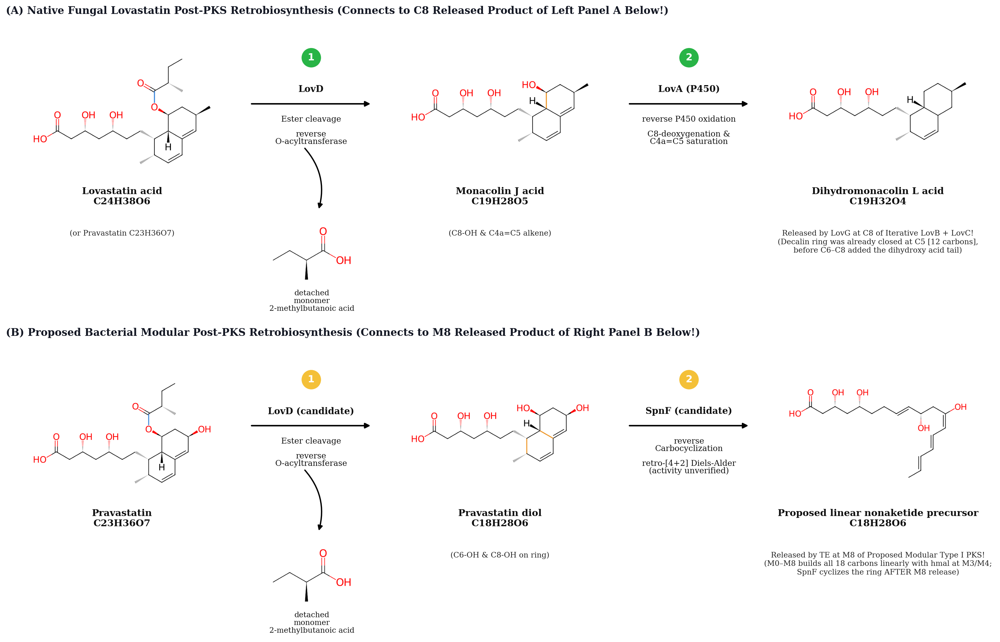

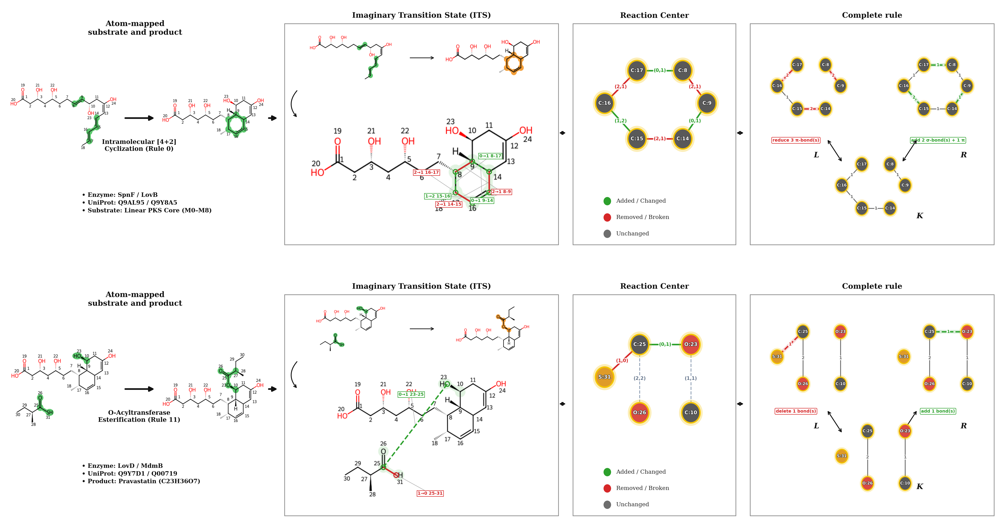

In [1]:
# Scenario 2 (Part 1): Why Native Fungal Biosynthesis vs. Our Proposed Modular PKS Route Differ in Post-PKS Steps
# Row (A) Native Fungal Lovastatin Pathway (3 Reverse Post-PKS Steps before C8->C0): Lovastatin (C24H36O5) --[1: LovD]--> Monacolin J acid (C19H28O5) --[2: LovA (P450)]--> Dihydromonacolin L acid (C19H32O4, released by LovG at C8) --[3: LovB/LovC (C8->C5 retro-DA)]--> C4 Pentaketide
# Row (B) Proposed Bacterial Modular Route (2 Reverse Post-PKS Steps before M8->M0): Pravastatin (C23H36O7) --[1: LovD]--> Pravastatin Diol (C18H28O6) --[2: SpnF candidate retro-DA]--> Proposed Linear Nonaketide Precursor (C18H28O6, released by M8-TE with C6/C8-OH already installed by M3/M4 hmal!)

lovastatin_acid = 'CC[C@H](C)C(=O)O[C@H]1C[C@@H](C)C=C2C=C[C@H](C)[C@H](CC[C@@H](O)C[C@@H](O)CC(=O)O)[C@@H]21'
monacolin_j_acid = 'C[C@H]1C=CC2=C[C@H](C)C[C@H](O)[C@H]2[C@H]1CC[C@@H](O)C[C@@H](O)CC(=O)O'
dml_acid = 'C[C@H]1C=CC2C[C@H](C)CC[C@H]2[C@H]1CC[C@@H](O)C[C@@H](O)CC(=O)O'

prav = 'CC[C@H](C)C(=O)O[C@H]1C[C@@H](O)C=C2C=C[C@H](C)[C@H](CC[C@@H](O)C[C@@H](O)CC(=O)O)[C@@H]21'
diol = 'C[C@H]1C=CC2=C[C@H](O)C[C@H](O)[C@H]2[C@H]1CC[C@@H](O)C[C@@H](O)CC(=O)O'
mono = 'CC=CC=CC=C(O)C[C@H](O)C=CCC[C@@H](O)C[C@@H](O)CC(=O)O'

b_lov1, _, det_lov_smi, _ = _find_step_broken_bonds_and_detached_monomer(lovastatin_acid, monacolin_j_acid, 11)
b_prav1, _, det1_smi, _ = _find_step_broken_bonds_and_detached_monomer(prav, diol, 11)
b_prav2, _, _, _ = _find_step_broken_bonds_and_detached_monomer(diol, mono, 0)

row1_native_steps = [
    {
        'from_smi': lovastatin_acid, 'broken_bonds': b_lov1, 'color_role': 'blue',
        'mol_title': 'Lovastatin acid\nC24H38O6', 'mol_subtitle': '(or Pravastatin C23H36O7)',
        'enzyme_label': 'LovD', 'op_line1': 'Ester cleavage', 'op_line2': 'reverse\nO-acyltransferase',
        'detached_smi': det_lov_smi, 'detached_name': '2-methylbutanoic acid',
    },
    {
        'from_smi': monacolin_j_acid, 'broken_bonds': [10], 'color_role': 'orange',
        'mol_title': 'Monacolin J acid\nC19H28O5', 'mol_subtitle': '(C8-OH & C4a=C5 alkene)',
        'enzyme_label': 'LovA (P450)', 'op_line1': 'reverse P450 oxidation', 'op_line2': 'C8-deoxygenation &\nC4a=C5 saturation',
        'detached_smi': None, 'detached_name': None,
    },
]

row2_modular_steps = [
    {
        'from_smi': prav, 'broken_bonds': b_prav1, 'color_role': 'blue',
        'mol_title': 'Pravastatin\nC23H36O7', 'mol_subtitle': '',
        'enzyme_label': 'LovD (candidate)', 'op_line1': 'Ester cleavage', 'op_line2': 'reverse\nO-acyltransferase',
        'detached_smi': det1_smi, 'detached_name': '2-methylbutanoic acid',
    },
    {
        'from_smi': diol, 'broken_bonds': b_prav2, 'color_role': 'orange',
        'mol_title': 'Pravastatin diol\nC18H28O6', 'mol_subtitle': '(C6-OH & C8-OH on ring)',
        'enzyme_label': 'SpnF (candidate)', 'op_line1': 'reverse\nCarbocyclization', 'op_line2': 'retro-[4+2] Diels-Alder\n(activity unverified)',
        'detached_smi': None, 'detached_name': None,
    },
]

fig = plt.figure(figsize=(17.5, 11.4), dpi=200, facecolor='white')
render_reaction_row_on_axes(
    fig, y_top=0.93, row_height=0.43, steps_spec=row1_native_steps,
    final_smi=dml_acid, final_title='Dihydromonacolin L acid\nC19H32O4',
    final_subtitle='Released by LovG at C8 of Iterative LovB + LovC!\n(Decalin ring was already closed at C5 [12 carbons],\nbefore C6–C8 added the dihydroxy acid tail)',
    badge_color='#28B446',
    row_header='(A) Native Fungal Lovastatin Post-PKS Retrobiosynthesis (Connects to C8 Released Product of Left Panel A Below!)',
)
render_reaction_row_on_axes(
    fig, y_top=0.45, row_height=0.43, steps_spec=row2_modular_steps,
    final_smi=mono, final_title='Proposed linear nonaketide precursor\nC18H28O6',
    final_subtitle='Released by TE at M8 of Proposed Modular Type I PKS!\n(M0–M8 builds all 18 carbons linearly with hmal at M3/M4;\nSpnF cyclizes the ring AFTER M8 release)',
    badge_color='#F4C038',
    row_header='(B) Proposed Bacterial Modular Post-PKS Retrobiosynthesis (Connects to M8 Released Product of Right Panel B Below!)',
)
plt.show()
plt.close(fig)

Saved Iterative vs. Modular PKS assembly-line comparison to: /data/lukecarlate/Retrobiosynthesis_SSBL/plots/reverse_peeling_pathway_inference.png


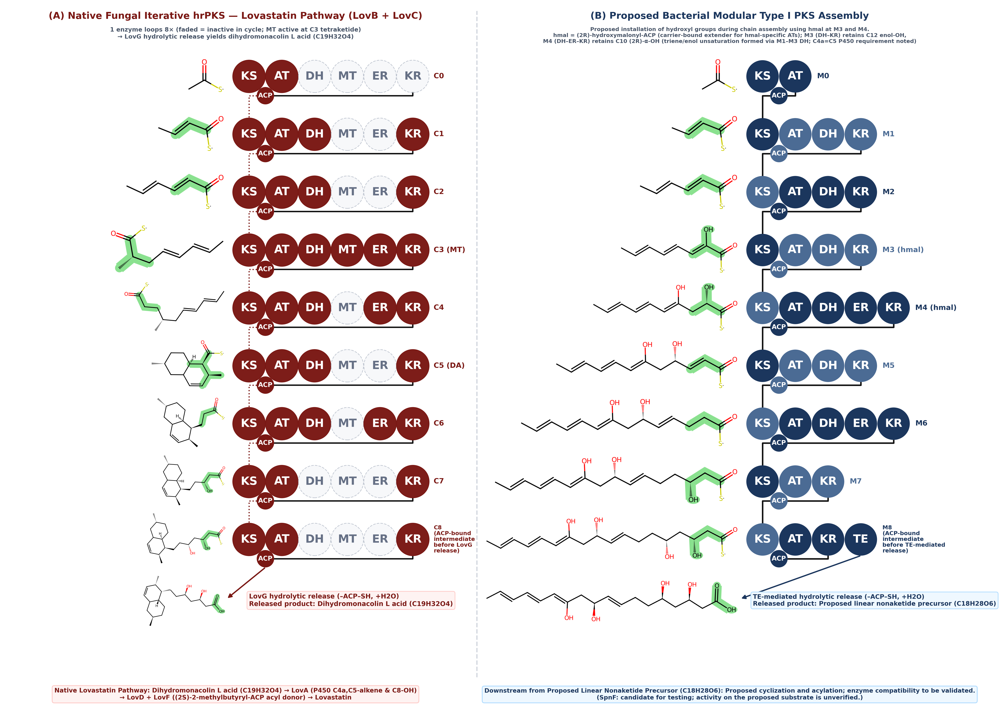

In [1]:
# Scenario 2 (Part 2): Side-by-Side Assembly-Line Diagram — Native Fungal Iterative hrPKS (LovB+LovC) vs. Bacterial Modular Type I PKS (M0-M8) for C18H28O6
from PIL import Image
render_iterative_vs_modular_pks_assembly_figure(str(REPO_ROOT / 'plots/reverse_peeling_pathway_inference.png'))
img_comp = Image.open(REPO_ROOT / 'plots/reverse_peeling_pathway_inference.png')
fig = plt.figure(figsize=(18, 14.2), dpi=180, facecolor='white')
ax = fig.add_axes([0, 0, 1, 1])
ax.axis('off')
ax.imshow(img_comp)
plt.show()
plt.close(fig)

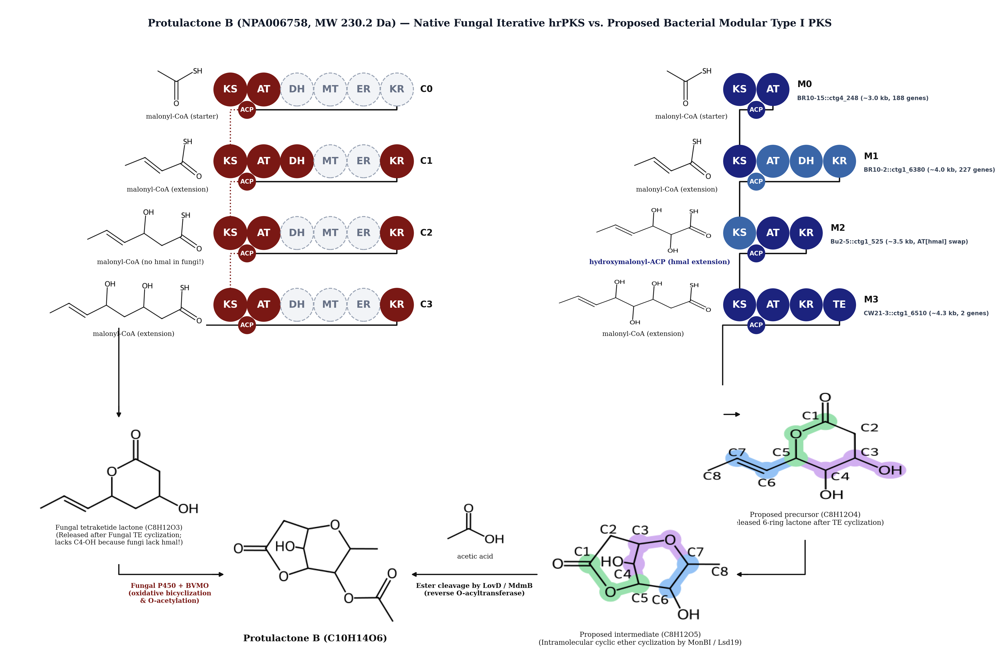

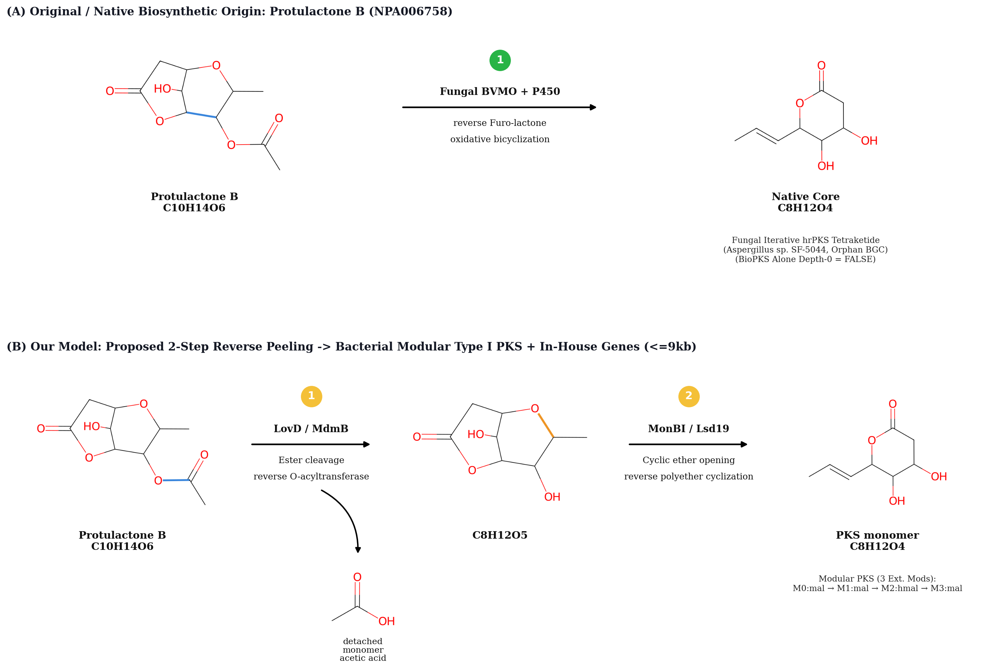

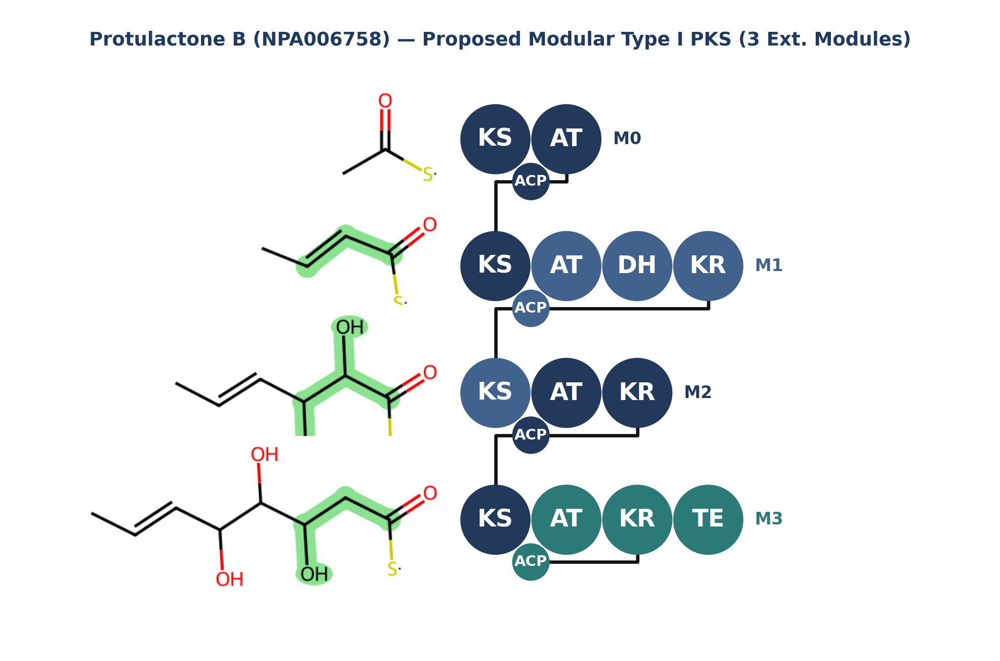

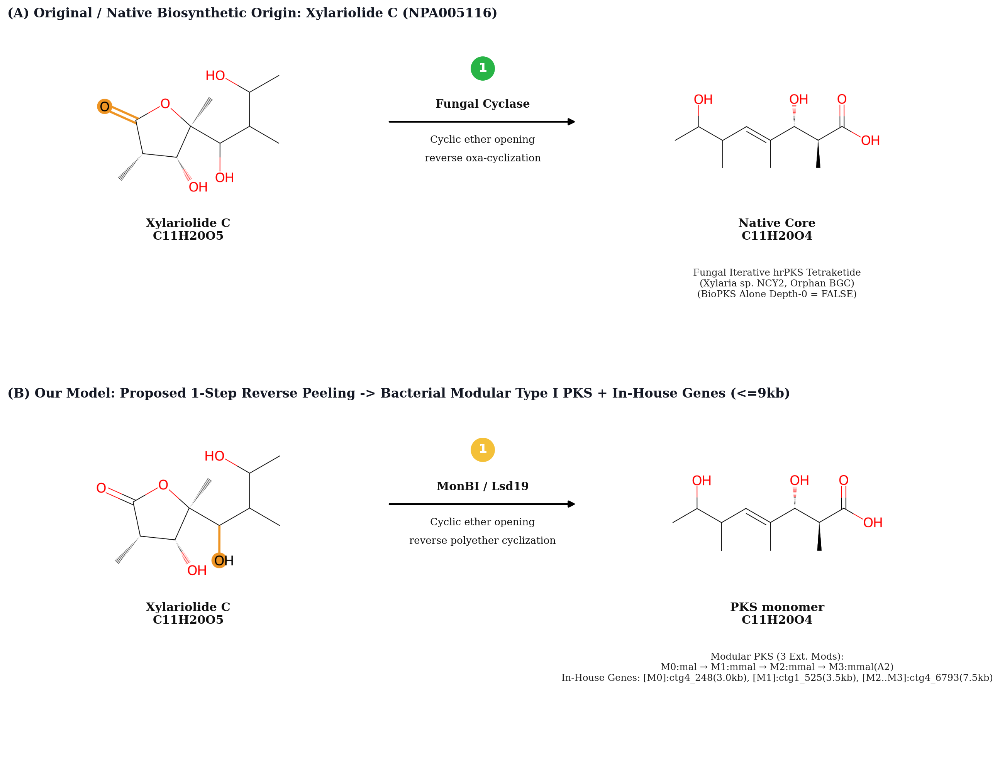

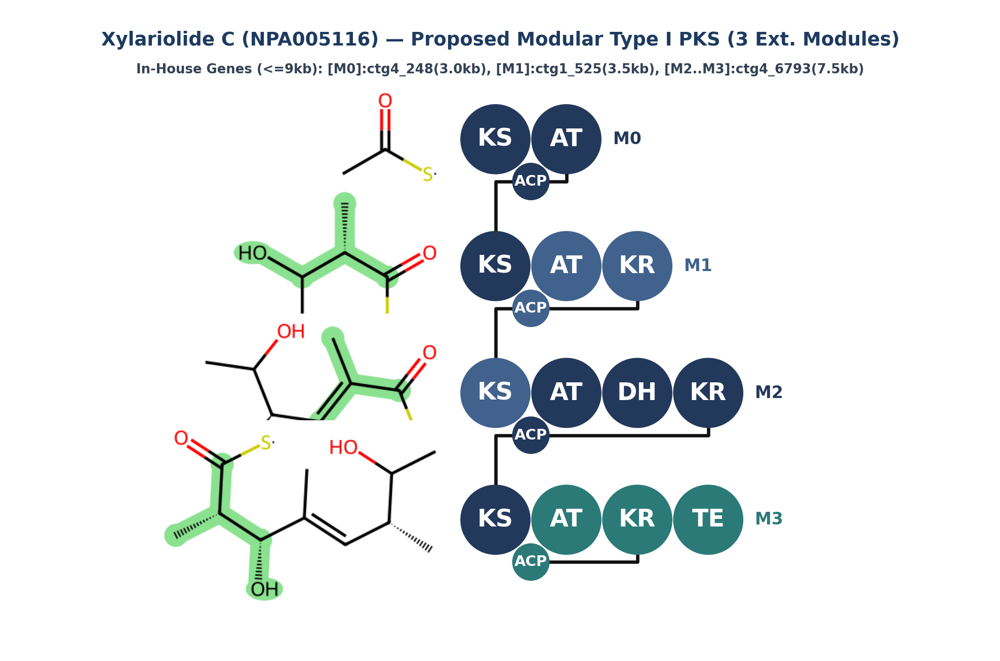

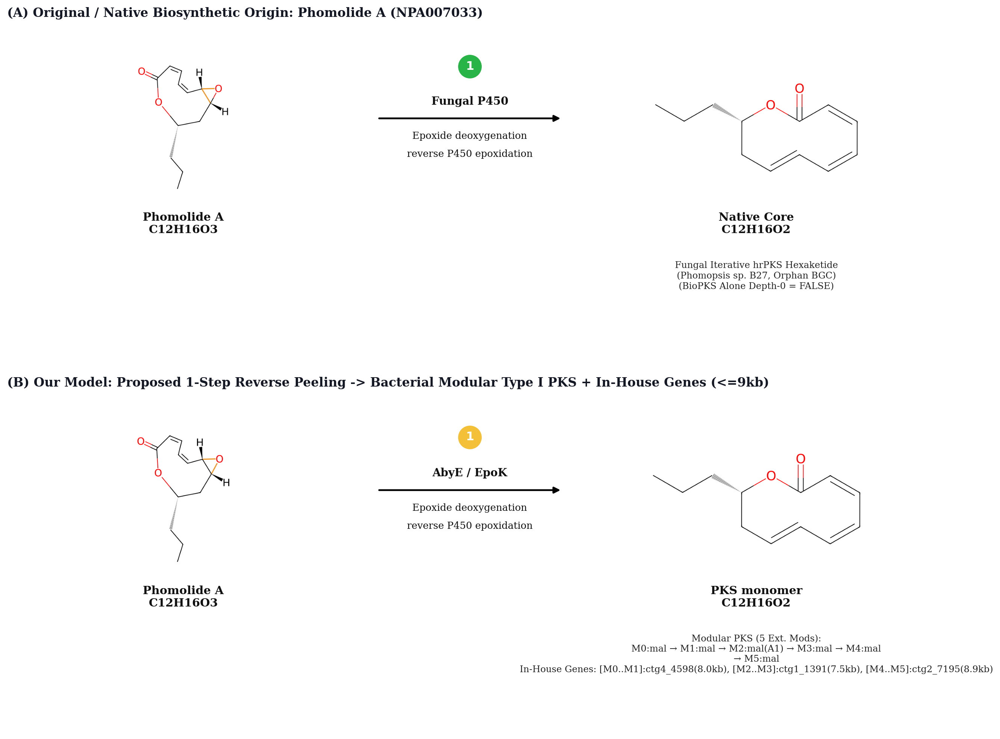

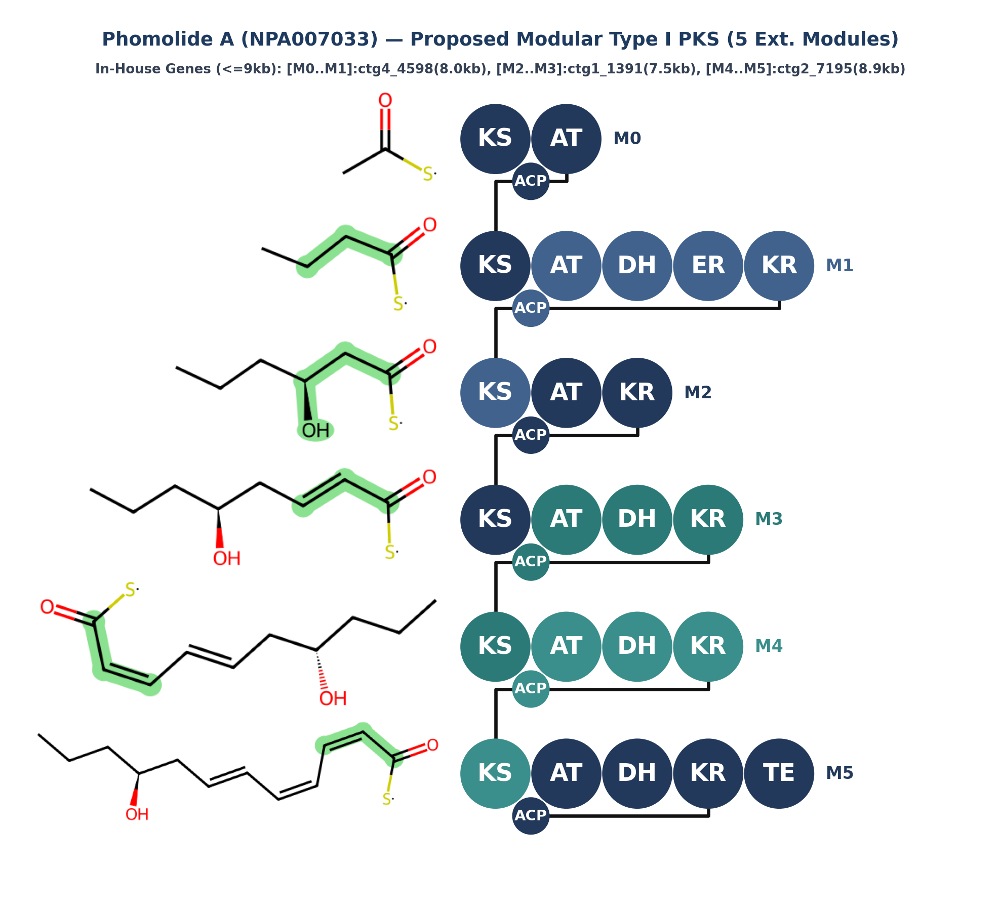

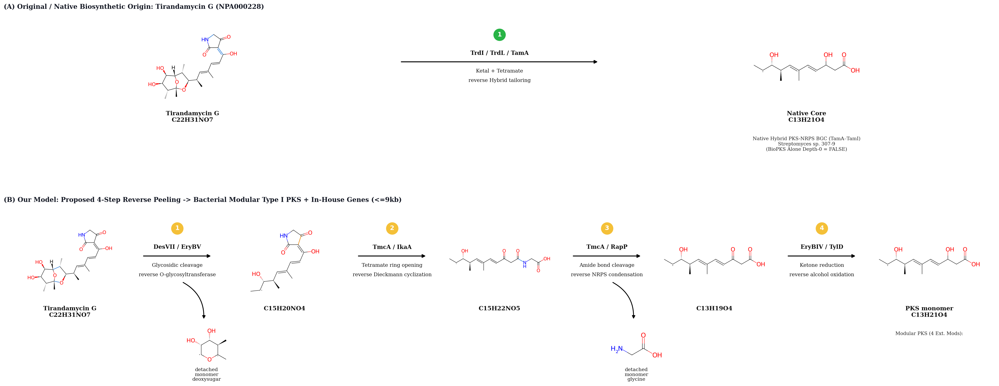

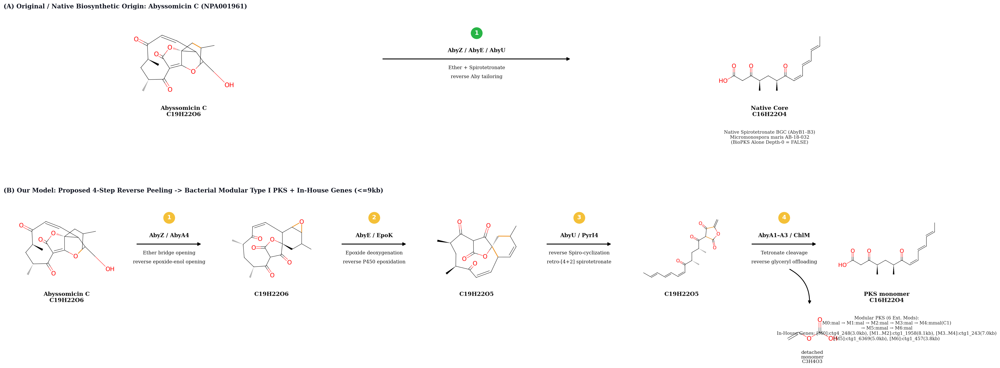

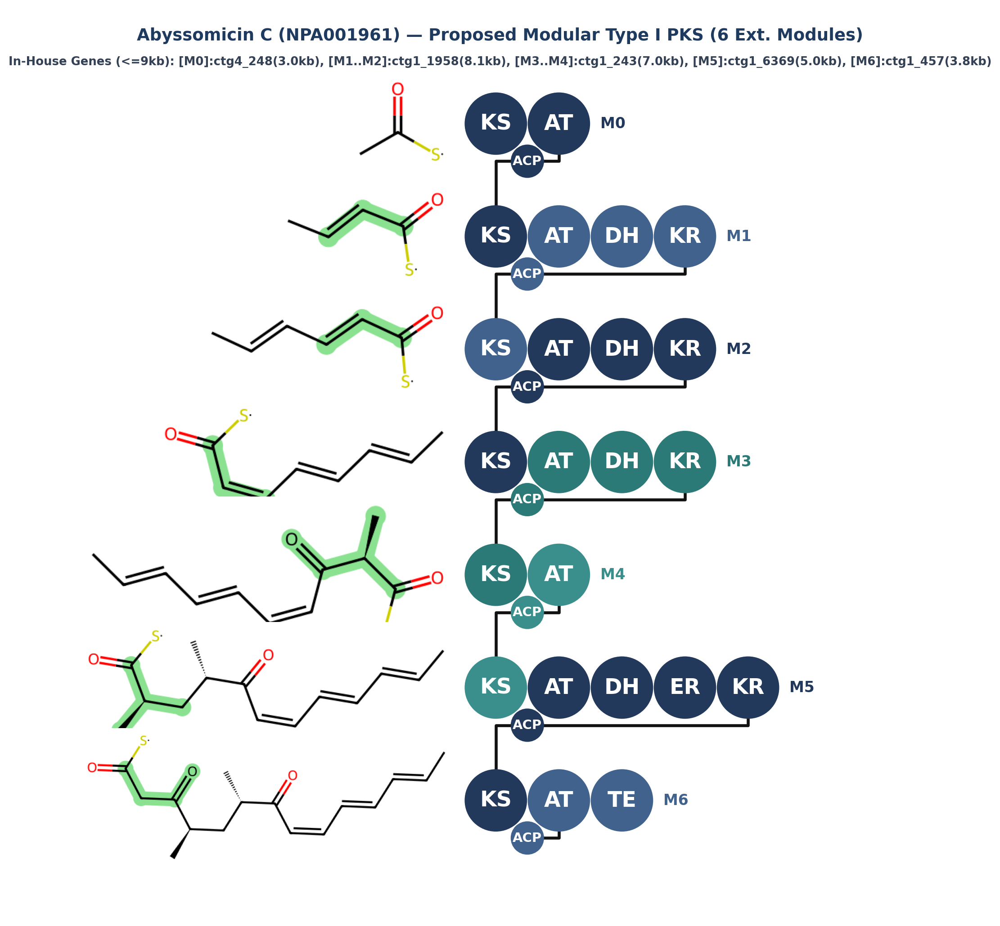

In [1]:
# Scenario 1 Portfolio: Paired Reaction Schemes + Modular Domain-Bubble Assembly Lines
np_df = pd.read_csv('/data/lukecarlate/max_subset/AntiPKgen/01_pksability_filter/data/npatlas_smiles.csv')

for npaid, name, native_enz, native_op1, native_op2, native_core_note in [
    ('NPA006758', 'Protulactone B', 'Fungal BVMO + P450', 'reverse Furo-lactone', 'oxidative bicyclization', 'Fungal Iterative hrPKS Tetraketide\n(Aspergillus sp. SF-5044, Orphan BGC)'),
    ('NPA005116', 'Xylariolide C', 'Fungal Cyclase', 'Cyclic ether opening', 'reverse oxa-cyclization', 'Fungal Iterative hrPKS Tetraketide\n(Xylaria sp. NCY2, Orphan BGC)'),
    ('NPA007033', 'Phomolide A', 'Fungal P450', 'Epoxide deoxygenation', 'reverse P450 epoxidation', 'Fungal Iterative hrPKS Hexaketide\n(Phomopsis sp. B27, Orphan BGC)'),
    ('NPA005290', 'Botryolide B', 'Fungal P450', 'Epoxide deoxygenation', 'reverse P450 epoxidation', 'Fungal Iterative hrPKS Pentaketide\n(Botryotrichum sp., Orphan BGC)'),
    ('NPA007544', 'Acremolide C', 'Orphan P450 / MT / NRPS', 'C-MT + OH + Dipeptide', 'reverse Hybrid tailoring', 'Orphan Hybrid PKS-NRPS BGC\n(Acremonium sp., Unsequenced BGC)'),
]:
    smi_t = str(np_df[np_df['NPAID'] == npaid].iloc[0]['SMILES'])
    res_t = run_reverse_peeling_search(model, smi_t, rules, device, max_depth=4, beam_width=6)
    steps_b, core_smi, f_title, f_sub = build_steps_spec_from_engine_result(res_t, target_name=name)
    m_t = Chem.MolFromSmiles(smi_t)
    f_t = Chem.rdMolDescriptors.CalcMolFormula(m_t)
    m_c = Chem.MolFromSmiles(core_smi)
    f_c = Chem.rdMolDescriptors.CalcMolFormula(m_c)
    steps_a = [{
        'from_smi': smi_t,
        'broken_bonds': steps_b[0]['broken_bonds'] if steps_b else [],
        'color_role': steps_b[0]['color_role'] if steps_b else 'orange',
        'mol_title': f'{name}\n{f_t}',
        'mol_subtitle': '',
        'enzyme_label': native_enz,
        'op_line1': native_op1,
        'op_line2': native_op2,
        'detached_smi': None,
        'detached_name': None,
    }]
    n_cols = max(2, len(steps_b) + 1)
    fig_w = max(13.5, 4.1 * n_cols + 1.8 * len(steps_b))
    fig = plt.figure(figsize=(fig_w, 10.8), dpi=190, facecolor='white')
    render_reaction_row_on_axes(
        fig, y_top=0.93, row_height=0.42, steps_spec=steps_a,
        final_smi=core_smi, final_title=f'Native Core\n{f_c}',
        final_subtitle=native_core_note + '\n(BioPKS Alone Depth-0 = FALSE)',
        badge_color='#28B446',
        row_header=f'(A) Original / Native Biosynthetic Origin: {name} ({npaid})',
    )
    render_reaction_row_on_axes(
        fig, y_top=0.45, row_height=0.43, steps_spec=steps_b,
        final_smi=core_smi, final_title=f_title,
        final_subtitle=f_sub,
        badge_color='#F4C038',
        row_header=f'(B) Our Model: Proposed {len(steps_b)}-Step Reverse Peeling -> Bacterial Modular Type I PKS + In-House Genes (<=9kb)',
    )
    plt.show()
    plt.close(fig)
    render_modular_pks_assembly_line_for_target(res_t, target_name=f'{name} ({npaid})')